<a href="https://colab.research.google.com/github/siyunggu/CXR_CV/blob/main/CXR_CV_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. 필요한 라이브러리 및 데이터 불러오기


In [2]:
import os, pandas as pd
from PIL import Image
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [3]:
# 코랩으로 하시는 분들
!pip install scikit-optimize imbalanced-learn -q
# 이거 안깔면 오류뜹니다. 그리고 데이터 드라이브에서 마운트하면 오래걸림

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 3.8 MB/s eta 0:00:00


In [4]:
# Colab에서 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# 이미지 데이터 불러오기
!cp "/content/drive/MyDrive/프로젝트/CV해커톤/img.zip" /content/

In [6]:
# 압축해제
!unzip -q /content/img.zip -d /content/img  #-d 뒤에는 압축 푼 파일명(일반적으로.zip만 지우기)

In [7]:
# 파일/폴더 목록이 잘 뜨는지 확인
os.listdir('/content/img')

['train', 'test', '__MACOSX']

In [8]:
print(os.listdir('/content/img/train')[:5])
print(os.listdir('/content/img/test')[:5])

['train_2238.png', 'train_3366.png', 'train_4134.png', 'train_0814.png', 'train_2522.png']
['test_0134.png', 'test_0271.png', 'test_0098.png', 'test_0263.png', 'test_0236.png']


In [9]:
# csv 데이터 불러오기
df1 = pd.read_csv('train.csv')
df2 = pd.read_csv('test.csv')
df3 = pd.read_csv('sample_submission.csv')

In [10]:
print("Train:", df1.shape, df1.columns.tolist())
print("Test:", df2.shape, df2.columns.tolist())
print("Sample:", df3.shape, df3.columns.tolist())

Train: (5216, 2) ['file_name', 'label']
Test: (624, 1) ['file_name']
Sample: (624, 2) ['file_name', 'label']


## 2. 이미지 전처리 설정하기

이미지를 모델에 넣기 전에 몇 가지 작업을 해야 합니다. 왜 이런 작업이 필요할까요?

우리가 가진 이미지들은 크기도 다르고, 어떤 건 컬러이고 어떤 건 흑백일 수도 있습니다. 하지만 딥러닝 모델은 모든 입력이 똑같은 형태여야 처리할 수 있어요.

baseline 코드에서는 Grayscale()로 이미지를 흑백으로 바꿉니다. 또한, 모든 이미지를 128×128 픽셀 크기로 통일하고 PyTorch가 이해할 수 있는 숫자 배열 형태로 바꿔줍니다.


In [11]:
# 이미지 크기 확인
Img = Image.open('/content/img/train/train_2550.png')
Img = np.array(Img)
print(Img.shape)

Img1 = Image.open('/content/img/test/test_0552.png')
Img1 = np.array(Img1)
print(Img1.shape)

(224, 224)
(936, 1350)


In [12]:
# train에서는 이미 크기와 여백이 통일된 상태. test에서는 각각의 이미지 크기가 다름

from collections import Counter

# CSV에 적힌 파일 목록 불러오기
train_df = pd.read_csv("/content/train.csv")
test_df = pd.read_csv("/content/test.csv")

# 이미지 크기 확인
def check_image_sizes(df, folder):
    sizes = []

    for filename in df["file_name"]:
        path = os.path.join(folder, filename)

        with Image.open(path) as img:
            sizes.append(img.size)  # (가로, 세로)

    return Counter(sizes)

train_sizes = check_image_sizes(
    train_df, "/content/img/train"
)
test_sizes = check_image_sizes(
    test_df, "/content/img/test"
)

print("Train 이미지 크기 종류:", len(train_sizes))
print("Train에서 많은 크기 TOP 5:", train_sizes.most_common(5))

print("\nTest 이미지 크기 종류:", len(test_sizes))
print("Test에서 많은 크기 TOP 5:", test_sizes.most_common(5))


Train 이미지 크기 종류: 1
Train에서 많은 크기 TOP 5: [((224, 224), 5216)]

Test 이미지 크기 종류: 598
Test에서 많은 크기 TOP 5: [((1112, 736), 3), ((1088, 576), 2), ((1368, 904), 2), ((1112, 600), 2), ((1232, 888), 2)]


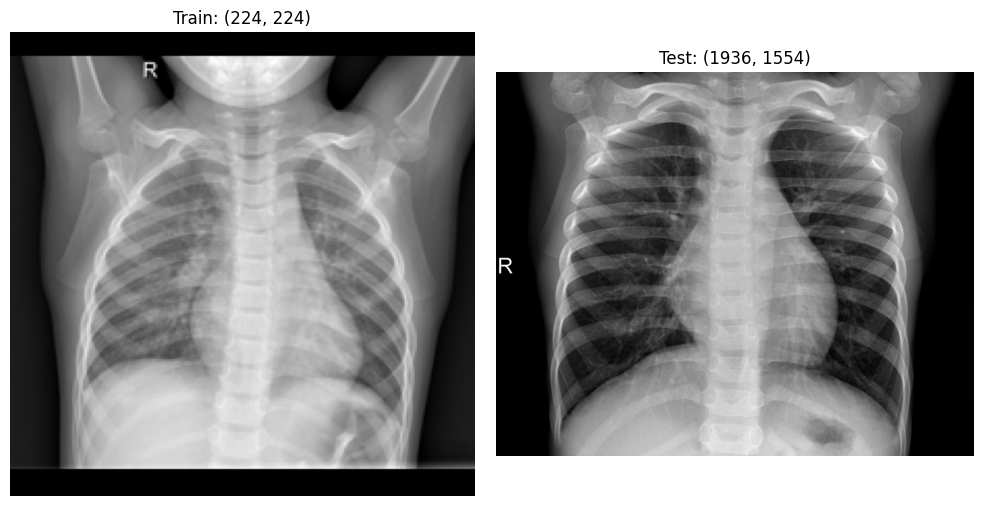

In [13]:
# traim test 실제 이미지 확인

import matplotlib.pyplot as plt


train_name = train_df["file_name"].iloc[0]
test_name = test_df["file_name"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, path, title in [
    (axes[0], os.path.join("/content/img/train", train_name), "Train"),
    (axes[1], os.path.join("/content/img/test", test_name), "Test")
]:
    img = Image.open(path).convert("L")
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{title}: {img.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [14]:
# 전처리

from PIL import Image, ImageOps
from torchvision import transforms

# 직사각형 이미지를 검은 여백으로 정사각형 만들기
class PadToSquare:
    def __call__(self, img):
        width, height = img.size

        # 이미 정사각형이면 그대로 사용
        if width == height:
            return img

        # 긴 변에 맞춰 짧은 변 양쪽에 검은 여백 추가
        size = max(width, height)
        left = (size - width) // 2
        top = (size - height) // 2
        right = size - width - left
        bottom = size - height - top

        return ImageOps.expand(
            img,
            border=(left, top, right, bottom),
            fill=0
        )


# 학습·검증·테스트에 공통으로 적용할 기본 전처리
base_transform = transforms.Compose([
    transforms.Grayscale(),
    PadToSquare(),
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])


## 3. 학습 데이터셋 만들기

이 부분은 우리의 학습 데이터를 정리하는 클래스입니다.

PyTorch에서는 데이터를 Dataset 클래스로 만들어야 합니다. 이 클래스는 세 가지 기능이 있어야 해요. 처음 시작할 때 CSV 파일을 읽어서 이미지 파일 이름들과 정답 라벨들을 기억해두고, "총 몇 개의 데이터가 있나요?"라고 물어볼 때 답해주고, "i번째 데이터를 주세요"라고 요청할 때 해당 이미지를 불러와서 전처리한 후 정답과 함께 돌려줍니다.

여기서 중요한 점은 이미지 파일을 미리 다 불러오지 않고, 필요할 때마다 하나씩 불러온다는 것입니다. 만약 이미지가 수천 개라면 메모리가 부족할 수 있거든요.


In [15]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Grayscale(),
    PadToSquare(),
    transforms.Resize((128, 128)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03)
    ),
    transforms.ToTensor()
])


In [16]:
class TrainCSV(Dataset):
    def __init__(self, csv_path="/content/train.csv",
                 root_dir="/content/img/train",
                 transform=None):
        df = pd.read_csv(csv_path)
        self.files = df["file_name"].tolist()
        self.labels = df["label"].astype(int).tolist()
        self.root = root_dir
        self.tf = transform if transform is not None else base_transform  #학습용과 검증용 데이터 따로 하기 위함

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img_path = os.path.join(self.root, self.files[i])
        img = Image.open(img_path).convert("L")
        x = self.tf(img)
        y = self.labels[i]
        return x, y


In [17]:
train_dataset = TrainCSV()

x, y = train_dataset[0]

print("이미지 텐서 크기:", x.shape)
print("레이블:", y)

이미지 텐서 크기: torch.Size([1, 128, 128])
레이블: 0


## 4. 테스트 데이터셋 만들기

해커톤에서의 테스트 데이터셋은 정답이 없습니다!

테스트 데이터는 우리가 예측해야 하는 데이터이기 때문에 당연히 정답을 모르죠. 그래서 이미지만 반환하고 라벨은 반환하지 않습니다.

이것이 바로 대회의 핵심입니다. 학습 데이터로 모델을 훈련시킨 후, 처음 보는 테스트 데이터에 대해 정답을 맞춰야 하는 거예요.


In [18]:
class TestCSV(Dataset):
    def __init__(self, csv_path="/content/test.csv",
                 root_dir="/content/img/test"):
        df = pd.read_csv(csv_path)
        self.files = df["file_name"].tolist()
        self.root = root_dir
        self.tf = base_transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img_path = os.path.join(self.root, self.files[i])
        img = Image.open(img_path).convert("L")
        x = self.tf(img)
        return x


In [19]:
test_dataset = TestCSV()

x = test_dataset[0]

print("테스트 이미지 텐서 크기:", x.shape)
print("테스트 데이터 개수:", len(test_dataset))

테스트 이미지 텐서 크기: torch.Size([1, 128, 128])
테스트 데이터 개수: 624


## 5. 데이터로더 설정하기

데이터셋을 만들었다면 이제 이것을 모델에게 효율적으로 전달해주는 DataLoader가 필요합니다.

왜 DataLoader가 필요할까요? 만약 이미지가 1000개라면, 1000개를 한 번에 모델에 넣을 수 있을까요? 아마 컴퓨터 메모리가 부족할 거예요. 그래서 32개씩 나누어서 처리하는 것입니다. 이렇게 나누어진 묶음을 '배치(batch)'라고 합니다.

batch_size=32는 한 번에 32개 이미지를 처리한다는 뜻입니다. shuffle=True는 학습 데이터의 순서를 섞어서 모델이 편향되지 않게 하고, shuffle=False는 테스트 데이터의 순서를 유지해야 제출할 때 파일명과 예측 결과가 올바르게 매칭되도록 합니다.


In [20]:
train_loader = DataLoader(
    TrainCSV("/content/train.csv", "/content/img/train"),
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    TestCSV("/content/test.csv", "/content/img/test"),
    batch_size=64,
    shuffle=False
)

## 6. 데이터 증강

In [21]:
from torchvision import transforms

# 학습 데이터에만 적용할 데이터 증강
train_transform = transforms.Compose([
    transforms.Grayscale(),
    PadToSquare(),
    transforms.Resize((128, 128)),

    # 이미지를 최대 5도까지 회전
    transforms.RandomRotation(degrees=5),

    # 이미지를 가로·세로 방향으로 최대 3% 이동
    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03)
    ),

    transforms.ToTensor()
])


In [22]:
# 데이터 증강 적용 확인
train_dataset = TrainCSV()

x, y = train_dataset[0]

print("이미지 텐서 크기:", x.shape)
print("레이블:", y)

이미지 텐서 크기: torch.Size([1, 128, 128])
레이블: 0


## 데이터 분리하기

In [23]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

# 전체 데이터에서 학습용 / 검증용 인덱스 분리
indices = list(range(len(train_dataset)))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=train_dataset.labels
)

print("학습 데이터 개수:", len(train_indices))
print("검증 데이터 개수:", len(val_indices))


학습 데이터 개수: 4172
검증 데이터 개수: 1044


In [24]:
# 학습용: 데이터 증강 적용
train_dataset = TrainCSV(transform=train_transform)

# 검증용: 기본 전처리만 적용
val_dataset = TrainCSV(transform=base_transform)

# 같은 인덱스 분할을 각각 적용
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

train_loader = DataLoader(
    train_subset, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_subset, batch_size=32, shuffle=False
)

print("학습 배치 수:", len(train_loader))
print("검증 배치 수:", len(val_loader))


학습 배치 수: 131
검증 배치 수: 33


In [25]:
from collections import Counter

print("전체 레이블:", Counter(train_dataset.labels))
print("학습 레이블:", Counter(train_dataset.labels[i] for i in train_indices))
print("검증 레이블:", Counter(val_dataset.labels[i] for i in val_indices))

전체 레이블: Counter({1: 3875, 0: 1341})
학습 레이블: Counter({1: 3099, 0: 1073})
검증 레이블: Counter({1: 776, 0: 268})


## 6. 간단한 CNN 모델 만들기

드디어 우리의 AI 모델을 만들 차례입니다! 이 모델은 CNN(Convolutional Neural Network)이라고 하는 이미지 분석에 특화된 신경망입니다.

CNN이 이미지를 어떻게 이해할까요? 사람이 사진을 볼 때를 생각해보세요. 먼저 선이나 모서리 같은 기본적인 특징을 파악하고, 그다음에 이것들이 조합되어 눈, 코, 입 같은 복잡한 형태를 인식하죠. CNN도 비슷하게 동작합니다.

합성곱층(Convolutional Layer)은 이미지에서 특징을 찾는 부분입니다. Conv2d(1, 16, 3, padding=1)은 흑백 이미지에서 16가지 특징을 찾는 필터로, 3×3 크기의 작은 창으로 이미지를 훑어가며 특징을 찾습니다. ReLU()는 음수 값을 0으로 만들어 모델이 더 잘 학습할 수 있게 돕고, MaxPool2d(2)는 이미지 크기를 절반으로 줄이면서 가장 중요한 특징만 남깁니다.

두 번째 합성곱층에서는 16개 특징을 32개의 더 복잡한 특징으로 변환하고, 다시 크기를 줄입니다. 최종적으로 128×128 이미지가 32×32 크기로 줄어듭니다.

완전연결층(Fully Connected Layer)은 추출된 특징들로 최종 분류를 하는 부분입니다. Flatten()으로 2차원 이미지를 1차원 배열로 펼치고, Linear로 추출된 모든 특징을 종합해서 최종적으로 2개 클래스 중 하나를 선택합니다.


In [26]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(32*32*32, 2))
    def forward(self, x): return self.fc(self.conv(x))


## 7. 모델 학습 준비하기

모델을 학습시키기 전에 몇 가지 설정이 필요합니다.

딥러닝은 계산량이 많기 때문에 GPU가 있다면 GPU를 사용하는 것이 훨씬 빠릅니다. 이 코드는 GPU가 있으면 자동으로 GPU를 사용하고, 없으면 CPU를 사용합니다.

CrossEntropyLoss()는 분류 문제에서 가장 많이 사용하는 손실함수입니다. 모델의 예측이 정답과 얼마나 다른지를 측정합니다. 이 값이 작을수록 모델이 더 정확하다는 뜻이에요.

Adam은 모델이 손실을 줄이는 방향으로 가중치를 조정하는 알고리즘입니다. 학습률 0.001은 한 번에 얼마나 크게 조정할지를 결정합니다. 너무 크면 학습이 불안정해지고, 너무 작으면 학습이 느려집니다.


In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 8. 모델 학습시키기

드디어 모델을 학습시킬 시간입니다! 이 과정을 단계별로 이해해봅시다.

에포크(Epoch)는 전체 학습 데이터를 한 번 다 보는 것을 의미합니다. 우리는 2 에포크만 돌리기 때문에, 모든 학습 이미지를 총 2번 보게 됩니다. 일반적으로는 더 많은 에포크가 필요하지만, 빠른 테스트를 위해 2번만 합니다.

학습 과정은 다음과 같습니다. model.train()으로 모델을 학습 모드로 설정하고, 배치마다 순전파(이미지를 모델에 넣어서 예측값을 얻기), 손실 계산(예측값과 정답을 비교해서 얼마나 틀렸는지 계산), 역전파(어떤 가중치를 어떻게 조정해야 손실이 줄어들지 계산), 가중치 업데이트(계산된 방향으로 가중치를 실제로 조정)를 반복합니다.

이 과정을 통해 모델이 점점 더 정확한 예측을 할 수 있게 됩니다.

In [28]:
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

# 모델 및 학습 설정
model = SimpleCNN().to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

# 학습
num_epochs = 5

# [추가 1] 에폭별 loss 기록용 리스트
history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}

for epoch in range(num_epochs):
    model.train()
    train_losses = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    # 검증
    model.eval()
    all_preds = []
    all_labels = []
    val_losses = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_losses.append(loss.item())

            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    train_loss = sum(train_losses) / len(train_losses)
    val_loss = sum(val_losses) / len(val_losses)

    # [추가 2] 에폭 결과 저장
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(accuracy)
    history["val_f1"].append(f1)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Accuracy: {accuracy:.4f} "
        f"| Val F1: {f1:.4f}"
    )


Epoch [1/5] | Train Loss: 0.2606 | Val Loss: 0.1506 | Val Accuracy: 0.9377 | Val F1: 0.9577
Epoch [2/5] | Train Loss: 0.1834 | Val Loss: 0.1682 | Val Accuracy: 0.9406 | Val F1: 0.9587
Epoch [3/5] | Train Loss: 0.1547 | Val Loss: 0.1165 | Val Accuracy: 0.9598 | Val F1: 0.9728
Epoch [4/5] | Train Loss: 0.1297 | Val Loss: 0.1048 | Val Accuracy: 0.9588 | Val F1: 0.9724
Epoch [5/5] | Train Loss: 0.1169 | Val Loss: 0.1216 | Val Accuracy: 0.9521 | Val F1: 0.9670


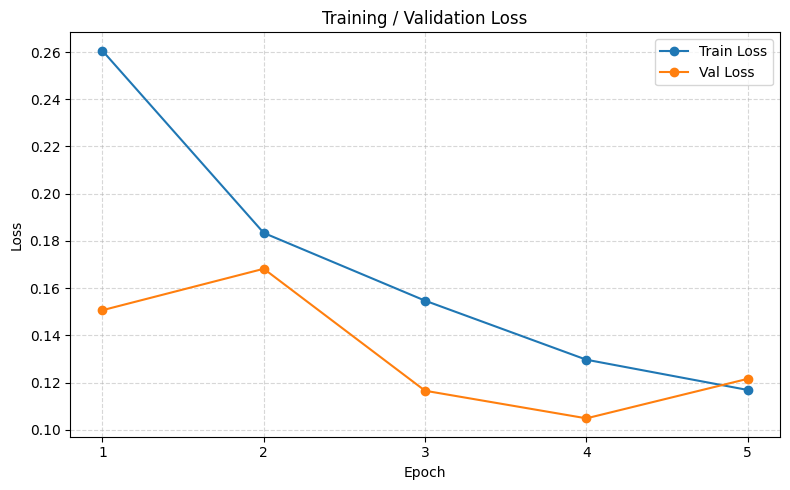

In [29]:
# 학습곡선 그래프
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Validation Loss")
plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

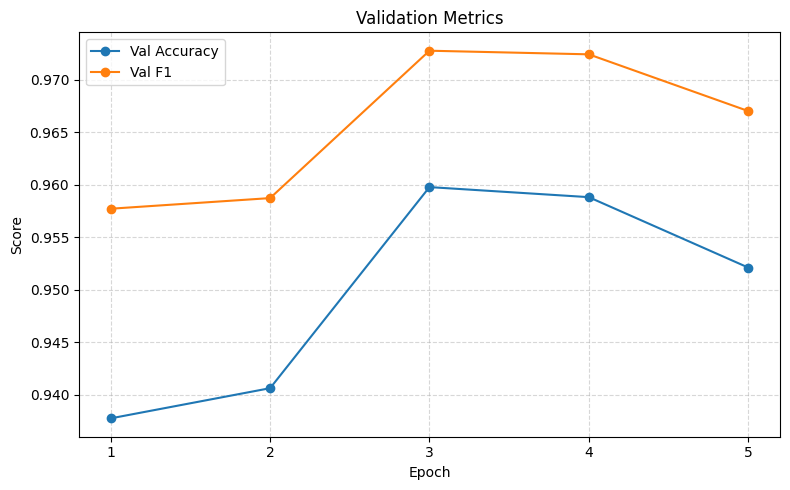

In [30]:
# Accuracy와 F1 그래프
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["val_acc"], marker="o", label="Val Accuracy")
plt.plot(epochs, history["val_f1"], marker="o", label="Val F1")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Metrics")
plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 9. 테스트 데이터 예측하기

학습이 끝났으니 이제 우리 모델이 얼마나 잘 학습했는지 테스트해볼 차례입니다.

model.eval()로 모델을 평가 모드로 바꿉니다. 학습할 때와 예측할 때는 모델의 동작이 약간 다르기 때문입니다. torch.no_grad()는 메모리를 절약하기 위한 설정으로, 예측할 때는 가중치를 업데이트할 필요가 없으니까 관련 계산을 하지 않습니다.

예측 과정은 테스트 이미지를 모델에 넣고, 모델이 각 클래스별 점수를 반환하면, argmax로 가장 높은 점수의 클래스를 선택합니다. 그리고 결과를 CPU로 옮기고 numpy 배열로 변환한 후, 모든 예측 결과를 하나의 리스트에 모읍니다.


In [31]:
model.eval()
all_preds = []
with torch.no_grad():
    for x in test_loader:
        x = x.to(device)
        preds = model(x).argmax(1).cpu().numpy()
        all_preds.extend(preds)

## 10. 제출 파일 만들기

마지막으로 우리의 예측 결과를 대회에 제출할 수 있는 형태로 만들어야 합니다.

대회에서는 보통 제출 양식을 제공합니다. sample_submission.csv 파일이 바로 그 양식이에요. 이 파일에는 테스트 이미지들의 파일명이 순서대로 들어있고, 우리는 여기에 예측한 라벨을 넣어주면 됩니다.

우리가 예측한 결과를 라벨 컬럼에 넣고, 새로운 CSV 파일로 저장합니다. 이 파일을 대회 사이트에 업로드하면 점수를 확인할 수 있습니다!


In [32]:
submission  = pd.read_csv("sample_submission.csv")
submission["label"] = all_preds

In [33]:
submission .to_csv("submit3.csv", index=False)